<h2 style="color:#FFA500";> Sensitivity Analysis — Oral-Domain Predictors Excluded (Cohort ≥65) </h2>

**Purpose.** Test whether the model retains useful discrimination using only
sociodemographic, systemic-health, and dietary predictors -- the kind of information a
non-dental setting (primary care, national health checkup) already has on hand, with no
self-reported oral-health or dental-behavior data.

**What changed vs. the main pipeline (OG_65+.ipynb):** exactly one thing --
5 oral-domain columns are dropped from `feature_cols` in the §6 encoding cell below
(`OR1`, `O_pain`, `MO4_00`, `BM1_0`, `brush_freq`). Data loading, cleaning, derivations
(eGFR, diabetes, hypertension, brush_freq), imputation, one-hot encoding, scaling, the
5-classifier Optuna tuning setup (50 trials, 5-fold stratified CV, AUPRC objective),
class-weighting, OOF-AUPRC model selection, bootstrap 95% CIs (2,000 resamples), and
Platt recalibration are all identical to the main pipeline.

**Not included** (out of scope for this sensitivity check, not part of the main
pipeline's core ML training/evaluation stage): Table 1 bivariate descriptive stats, SHAP
importance, VIF collinearity diagnostics, the inferential (survey-weighted) logistic
regression, sex-stratified discrimination/calibration, the DeLong test, and decision
curve analysis. See `OG_65+.ipynb` for those.


<h2 style="color:yellow";> 1. Load Packages </h2>


In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

<h2 style="color:yellow";> 2. Load Dataset </h2>

Load KNHANES survey data (2020–2024) across five annual CSV files.


In [2]:
CSV_DIR = '../csv'

df_hn24 = pd.read_csv(f'{CSV_DIR}/HN24_all.csv', low_memory=False)
df_hn23 = pd.read_csv(f'{CSV_DIR}/HN23_all.csv', low_memory=False)
df_hn22 = pd.read_csv(f'{CSV_DIR}/HN22_all.csv', low_memory=False)
df_hn21 = pd.read_csv(f'{CSV_DIR}/HN21_all.csv', low_memory=False)
df_hn20 = pd.read_csv(f'{CSV_DIR}/HN20_all.csv', low_memory=False)


df = pd.concat([df_hn20, df_hn21, df_hn22, df_hn23, df_hn24], ignore_index=True)
print(df.shape)
print(df.columns.tolist())
print(df.head())


(34640, 1188)
['mod_d', 'ID', 'ID_fam', 'year', 'region', 'town_t', 'apt_t', 'psu', 'sex', 'age', 'age_month', 'incm', 'ho_incm', 'incm5', 'ho_incm5', 'edu', 'occp', 'wt_hs', 'wt_itvex', 'wt_oe', 'wt_ntr', 'wt_tot', 'wt_oent', 'kstrata', 'cfam', 'genertn', 'allownc', 'house', 'live_t', 'ainc_unit1', 'ainc_1', 'ainc', 'marri_1', 'marri_2', 'fam_rela', 'tins', 'npins', 'ID_F', 'ID_M', 'D_1_1', 'D_2_1', 'D_2_wk', 'DI1_dg', 'DI1_ag', 'DI1_pr', 'DI1_pt', 'DI1_2', 'DI2_dg', 'DI2_ag', 'DI2_pr', 'DI2_pt', 'DI2_2', 'DI3_dg', 'DI3_ag', 'DI3_pr', 'DI3_pt', 'DI3_2', 'DI4_dg', 'DI4_pr', 'DI4_pt', 'DI5_dg', 'DI5_ag', 'DI5_pr', 'DI5_pt', 'DI6_dg', 'DI6_ag', 'DI6_pr', 'DI6_pt', 'DM1_dg', 'DM1_pr', 'DM1_pt', 'DM2_dg', 'DM2_ag', 'DM2_pr', 'DM2_pt', 'DM3_dg', 'DM3_ag', 'DM3_pr', 'DM3_pt', 'DM4_dg', 'DM4_ag', 'DM4_pr', 'DM4_pt', 'DJ2_dg', 'DJ2_ag', 'DJ2_pr', 'DJ2_pt', 'DJ4_dg', 'DJ4_ag', 'DJ4_pr', 'DJ4_pt', 'DJ4_3', 'DE2_dg', 'DE2_ag', 'DE2_pr', 'DE2_pt', 'DE1_dg', 'DE1_ag', 'DE1_pr', 'DE1_pt', 'DE1_3', '

<h3 style="color:yellow";> 2.1 Feature Selection & Age Filtering </h3>

Same `raw_columns` and age filter (>= 65) as the main pipeline. The oral-domain columns are still loaded here -- `BM1_1`-`BM1_8` feed the `brush_freq` derivation in §4.3, and `OR1`/`O_pain`/`MO4_00`/`BM1_0` are cleaned identically to the main pipeline -- they are excluded later, only at the §6 `feature_cols` step.


In [3]:
raw_columns = [
    'year', 'age', 'sex',
    # SES / demographics
    'ho_incm', 'edu', 'occp', 'marri_1', 'marri_2', 'genertn', 'fam_rela', 'house', 'cfam', 'live_t', 'tins',
    'region', 'town_t',
    # Disease diagnoses (sentinel 8/9 → NaN)
    'DE1_dg',
    # Lab values
    'HE_HbA1c', 'HE_BMI', 'HE_crea',
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    # Urinalysis
    'HE_Upro', 'HE_Ucrea',
    # Lifestyle
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1',
    # Secondhand smoke exposure, indoor workplace (sentinel 8/9 → NaN)
    'BS12_1',
    # Dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ',
    # Dental
    'OR1',
    'O_pain',
    'MO4_00',
    'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8',
    # Target
    'O_TC',
    # survey design (not modelled; weighted inference only)
    'wt_itvex', 'psu', 'kstrata',
]
# HE_obe    excluded: redundant with HE_BMI (NaN%/VIF computed in §4.1.1)
# DI4_dg    excluded: -inf sentinel in raw data, unreliable (NaN%/VIF computed in §4.1.1)
# DE1_4     excluded: high missingness, insufficient coverage for modelling (NaN%/VIF computed in §4.1.1)
# HE_wc     excluded: collinear with HE_BMI (NaN%/VIF computed in §4.1.1); HE_BMI retained as standard measure
# HE_glu    excluded: collinear with HE_HbA1c / diabetes (both measure glycaemic control); redundant
#            (NaN%/VIF computed in §4.1.1)
# BS3_1     excluded: high missingness, N/A for age < 19 in general population (NaN%/VIF computed in §4.1.1)
# BD2_1     excluded: high missingness, N/A for non-drinkers (NaN%/VIF computed in §4.1.1)
# LW_ms     excluded: high missingness, N/A for males (NaN%/VIF computed in §4.1.1); post_menopause feature dropped
# N_EN      excluded: total energy intake — collinear with the component dietary intakes (NaN%/VIF computed in §4.1.1); dropped from both models

age_threshold = 65
df_subset = df[raw_columns].copy()
df_subset = df_subset[df_subset['age'] >= age_threshold]
print(df_subset.shape)
print(df_subset.columns.tolist())

(9003, 57)
['year', 'age', 'sex', 'ho_incm', 'edu', 'occp', 'marri_1', 'marri_2', 'genertn', 'fam_rela', 'house', 'cfam', 'live_t', 'tins', 'region', 'town_t', 'DE1_dg', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2', 'HE_Upro', 'HE_Ucrea', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ', 'OR1', 'O_pain', 'MO4_00', 'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8', 'O_TC', 'wt_itvex', 'psu', 'kstrata']


<h2 style="color:#FFA500";> 3. Target Variable — Cleaning & Binary Label </h2>

Clean `O_TC` (total tooth count) and produce the binary classification target `O_TC_` (1 if tooth count < 20).


In [4]:
print(df_subset[pd.to_numeric(df_subset['O_TC'], errors='coerce').isna()]['O_TC'].unique())
# ^ finds all non numeric codes in the O_TC column and displays what those 'errors' were, in this case it 
# was ['-1.80E+308']

df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
# -1.80E+308 overflows float64 and becomes -inf (not NaN), so replace both infinities explicitly
df_subset['O_TC'] = df_subset['O_TC'].replace([np.inf, -np.inf], np.nan)

before_drop = len(df_subset)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows dropped (NaN O_TC): {before_drop - len(df_subset)}")
# ^ to know how many rows were dropped because of NaN; not required to the code --  just to visualize

df_subset['O_TC_'] = (df_subset['O_TC'] < 20).astype(int)
# ^ a lot of research papers determined O_TC value below 20 is considered impactful to the normal
# chewing and digestion problems. 
# "astype(int) --> converts True = 1 and False = 0"

label_counts    = df_subset['O_TC_'].value_counts()
# ^ counts how many values are there in the new 'O_TC_' column of 0s and 1s 
label_0         = label_counts[0]
label_1         = label_counts[1]

print(f"Age filter: >= {age_threshold}")
print(f"Label 0 (≥20 teeth): {label_0}")
print(f"Label 1 (<20 teeth): {label_1}")
print(df_subset['O_TC'].value_counts(dropna=False).head(20))

print(f"NaN count: {df_subset['O_TC'].isna().sum()}")

[nan '-1.80E+308']
Rows dropped (NaN O_TC): 1299
Age filter: >= 65
Label 0 (≥20 teeth): 4346
Label 1 (<20 teeth): 3358
O_TC
0.0     764
28.0    634
27.0    500
26.0    499
25.0    450
24.0    448
23.0    393
22.0    364
21.0    312
20.0    265
19.0    240
18.0    191
29.0    189
16.0    183
17.0    180
15.0    139
12.0    138
4.0     138
14.0    137
30.0    131
Name: count, dtype: int64
NaN count: 0


<h2 style="color:#FFA500";> 4. Missing Value Audit & Invalid-Code Replacement </h2>

Replace reserved refusal/non-applicable codes (8, 9, 88, 99, 888, 999) with `NaN` before modelling. Identical to the main pipeline.


In [5]:
# Disease diagnoses: 8 = not applicable (children/adolescents), 9 = refused/missing
disease_cols = ['DE1_dg']

# Survey ordinal / binary: 8 = not applicable, 9 = refused/missing
# BD1 (lifetime drinking experience, >=1 full drink, excl. ceremonial sips):
#   1 = NEVER drank, 2 = Yes, 8 = N/A (child), 9 = unknown / no response.
#   NOTE THE DIRECTION -- 1 means never. Verified against the KNHANES skip pattern:
#   BD2_1 (drinking frequency) is 100% N/A when BD1 == 1 vs 29% when BD1 == 2.
#   Recoded to 1=drinker / 0=never in the modelling cells (map({1: 0, 2: 1})).
# HE_Upro (proteinuria): 9 = missing (valid values 0–5)
# O_pain: dental pain perception; 0=no pain, 1=pain
# MO4_00 (dental visit past year): 9 = missing
# BM1_0 (toothbrushing yesterday): 9 = missing
# BM1_1–BM1_8 (brushing timing): 8 = N/A (if BM1_0 == 0), 9 = missing
# BS12_1 (indoor secondhand smoke at workplace, past week): 1=yes, 2=no; 8=N/A, 9=missing
survey_cols = ['edu', 'ho_incm', 'occp', 'marri_1', 'house', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'L_BR_FQ', 'HE_Upro', 'OR1', 'O_pain',
               'MO4_00', 'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8']

# Lab continuous: coerce + overflow-sentinel removal (large float placeholders → NaN)
lab_cols = [
    'HE_HbA1c', 'HE_BMI', 'HE_crea',
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    'HE_Ucrea',
]

# Dietary continuous
diet_cols = ['N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR']

# Coerce to numeric first: HN24 loads these columns as strings (its overflow-sentinel
# value forces object dtype), so the numeric-keyed .replace({8: nan, ...}) below would
# silently no-op on every 2024 row without this (mirrors the all_lab coercion pattern below).
df_subset[disease_cols + survey_cols] = df_subset[disease_cols + survey_cols].apply(pd.to_numeric, errors='coerce')

df_subset[disease_cols] = df_subset[disease_cols].replace({8: np.nan, 9: np.nan, 88: np.nan, 99: np.nan})
df_subset[survey_cols]  = df_subset[survey_cols].replace({8: np.nan, 9: np.nan, 88: np.nan, 99: np.nan})
df_subset[survey_cols]  = df_subset[survey_cols].replace([np.inf, -np.inf], np.nan)

all_lab = lab_cols + diet_cols
df_subset[all_lab] = df_subset[all_lab].apply(pd.to_numeric, errors='coerce')
df_subset[all_lab] = df_subset[all_lab].where(df_subset[all_lab].abs() < 1e10, np.nan)

df_subset.loc[df_subset['HE_crea'] <= 0, 'HE_crea'] = np.nan

# LS_VEG1/LS_FRUIT are frequency CODES (1=>=3x/day ... 9=almost never), not grams -- they
# ride along in diet_cols for the generic numeric-coerce/overflow pass above, but that pass
# only strips overflow sentinels, not this variable's OWN missing code. 99 = "don't know/no
# response" here (verified: 6 respondents pooled across 2020-2024 carry the literal value
# 99), which the overflow check (abs >= 1e10) does not catch.
df_subset[['LS_VEG1', 'LS_FRUIT']] = df_subset[['LS_VEG1', 'LS_FRUIT']].replace({99: np.nan})

# D13: nominal/count cols outside survey_cols still carried sentinels
# (verified in data: tins has 99, live_t has 9, all three have a stray -inf)
# Coerce to numeric first: HN24 loads these as strings too (same overflow-sentinel
# issue as disease_cols/survey_cols above), so cfam in particular was silently
# carrying the raw '-1.80E+308' string past the inf-replace below.
df_subset[['cfam', 'tins', 'live_t']] = df_subset[['cfam', 'tins', 'live_t']].apply(pd.to_numeric, errors='coerce')
df_subset[['cfam', 'tins', 'live_t']] = df_subset[['cfam', 'tins', 'live_t']].replace([np.inf, -np.inf], np.nan)
df_subset['tins']   = df_subset['tins'].replace({99: np.nan})   # 99 = missing (valid: 10/20/30)
df_subset['live_t'] = df_subset['live_t'].replace({9: np.nan})  # 9 = missing (valid: 1-4)
df_subset['cfam']   = df_subset['cfam'].replace({9: np.nan})    # 9 = missing sentinel (valid: 1-6)

# marri_2 / genertn / fam_rela: added nominal SES vars with COLUMN-SPECIFIC sentinels.
# They can't join the blanket survey_cols replace above because fam_rela's 9 is a VALID
# category (sibling), not a missing code -- a blanket {8,9,88,99}->NaN would destroy it.
# Coerce first (HN24 loads these as strings via the overflow sentinel, same as cfam/tins).
df_subset[['marri_2', 'genertn', 'fam_rela']] = df_subset[['marri_2', 'genertn', 'fam_rela']].apply(pd.to_numeric, errors='coerce')
df_subset[['marri_2', 'genertn', 'fam_rela']] = df_subset[['marri_2', 'genertn', 'fam_rela']].replace([np.inf, -np.inf], np.nan)
df_subset['marri_2']  = df_subset['marri_2'].replace({8: np.nan, 88: np.nan, 99: np.nan})  # 8/88 = N/A (unmarried), 99 = missing (valid: 1-4)
df_subset['genertn']  = df_subset['genertn'].replace({9: np.nan})                           # 9 = missing (valid: 1-7)
df_subset['fam_rela'] = df_subset['fam_rela'].replace({99: np.nan})                         # 99 = missing (valid: 1-10, incl. 9 = sibling)

# marri_2 gets EXPLICIT levels so marital status is fully encoded by ONE variable:
#   0   = never married (marri_1 == 2; marri_2 is structurally N/A for them)
#   1-4 = KNHANES detail (1 married-cohabiting, 2 married-separated, 3 widowed, 4 divorced)
#   5   = married but marital detail missing (genuine non-response among marri_1 == 1)
# marri_1 is then an exact function of marri_2 (marri_1 == 2 <=> marri_2 == 0), so it is
# NOT carried as a separate predictor in either arm -- the never-married contrast is read
# off the marri_2_0 dummy. Previously marri_1 + marri_2 together silently dropped all 380
# never-married respondents from every complete-case model AND left marri_1 zero-variance,
# where §11's inestimable-column guard removed it without comment.
df_subset.loc[df_subset['marri_1'] == 2, 'marri_2'] = 0
df_subset.loc[(df_subset['marri_1'] == 1) & df_subset['marri_2'].isna(), 'marri_2'] = 5
print("marri_2 levels after recode (0 = never married, 5 = married/detail missing):")
print(df_subset['marri_2'].value_counts(dropna=False).sort_index())
# region (1-17) and town_t (1/2): verified clean, no sentinel codes

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in disease_cols + survey_cols + lab_cols + diet_cols:
    count = df_subset[col].isna().sum()
    pct   = (count / total) * 100
    print(f"  {col:<15}: {count:>5}  ({pct:.1f}%)")

marri_2 levels after recode (0 = never married, 5 = married/detail missing):
marri_2
0.0      69
1.0    5150
2.0      77
3.0    1956
4.0     443
5.0       8
NaN       1
Name: count, dtype: int64
NaN counts per column after cleaning:
  DE1_dg         :     6  (0.1%)
  edu            :   677  (8.8%)
  ho_incm        :    53  (0.7%)
  occp           :   875  (11.4%)
  marri_1        :     1  (0.0%)
  house          :     9  (0.1%)
  sm_presnt      :   272  (3.5%)
  BD1            :   249  (3.2%)
  pa_aerobic     :   900  (11.7%)
  BP1            :   278  (3.6%)
  BS12_1         :   271  (3.5%)
  L_BR_FQ        :   596  (7.7%)
  HE_Upro        :   182  (2.4%)
  OR1            :     0  (0.0%)
  O_pain         :     0  (0.0%)
  MO4_00         :   277  (3.6%)
  BM1_0          :   274  (3.6%)
  BM1_1          :   527  (6.8%)
  BM1_2          :   527  (6.8%)
  BM1_3          :   527  (6.8%)
  BM1_4          :   527  (6.8%)
  BM1_5          :   527  (6.8%)
  BM1_6          :   527  (6.8%)
  BM1_

<h3 style="color:yellow";> 4.2 Derived Feature — eGFR (CKD-EPI 2021) </h3>

Replace raw serum creatinine with estimated Glomerular Filtration Rate (eGFR). Identical to the main pipeline.


In [6]:
def calculate_egfr(row):
    scr = row['HE_crea']
    age = row['age']
    sex = row['sex']   # KNHANES: 1 = male, 2 = female

    if pd.isna(scr) or pd.isna(sex):
        return np.nan

    if sex == 2:   # female
        kappa, alpha, sex_factor = 0.7, -0.241, 1.012
    else:          # male
        kappa, alpha, sex_factor = 0.9, -0.302, 1.0

    ratio = scr / kappa
    return (142
            * (min(ratio, 1) ** alpha)
            * (max(ratio, 1) ** -1.200)
            * (0.9938 ** age)
            * sex_factor)

df_subset['eGFR'] = df_subset.apply(calculate_egfr, axis=1)
df_subset = df_subset.drop(columns=['HE_crea'], errors='ignore')
# sex is retained — used as a feature in the ML model and as a covariate in the inferential model

<h3 style="color:yellow;"> 4.3 Derived Behavioral & Clinical Flags — Diabetes, Hypertension & Brushing </h3>

Derive `diabetes`, `hypertension`, and `brush_freq`. Identical to the main pipeline -- `brush_freq` is still computed here; it is dropped only at the §6 `feature_cols` step below, since it is one of the 5 excluded oral-domain features.


In [7]:
# Combined diabetes: diagnosed (DE1_dg == 1) OR HbA1c ≥ 6.5%
# NaN comparisons return False, so OR logic is safe — only set NaN when both sources are missing
diagnosed = (df_subset['DE1_dg'] == 1)
hba1c_pos = (df_subset['HE_HbA1c'] >= 6.5)
df_subset['diabetes'] = (diagnosed | hba1c_pos).astype(float)

both_missing = df_subset['DE1_dg'].isna() & df_subset['HE_HbA1c'].isna()
df_subset.loc[both_missing, 'diabetes'] = np.nan
df_subset = df_subset.drop(columns=['DE1_dg'], errors='ignore')

# Hypertension binary: SBP ≥ 140 OR DBP ≥ 90 (standard clinical threshold)
# NaN in either BP column → NaN result
sbp_pos = (df_subset['HE_sbp'] >= 140)
dbp_pos = (df_subset['HE_dbp'] >= 90)
df_subset['hypertension'] = (sbp_pos | dbp_pos).astype(float)

both_bp_missing = df_subset['HE_sbp'].isna() & df_subset['HE_dbp'].isna()
df_subset.loc[both_bp_missing, 'hypertension'] = np.nan

# BM1_1–BM1_8: binary flags for each brushing occasion → sum = brushing frequency count (0–8)
bm1_cols = ['BM1_1','BM1_2','BM1_3','BM1_4','BM1_5','BM1_6','BM1_7','BM1_8']
df_subset['brush_freq'] = df_subset[bm1_cols].sum(axis=1, min_count=1)
# Non-brushers (BM1_0 == 0) have all 8 slots coded N/A → NaN sum; their true frequency is 0.
df_subset.loc[df_subset['BM1_0'] == 0, 'brush_freq'] = 0
# Remaining brush_freq NaN = BM1_0 itself missing (median-imputed downstream)

# interdental dropped: BM2_1/BM2_3 are absent from the HN23 & HN24 files, so the feature
# is 100% missing for all of 2023 and the entire 2024 test year — degenerate, removed.

# Brushing is modelled exactly as KNHANES records it: BM1_0 (brushed yesterday, 0/1) and
# brush_freq (occasions yesterday, 0-8). Edentulous respondents are NOT given a separate
# category and are NOT dropped -- they answer BM1_0 like anyone else and stay in the sample.

# ── Diabetes & Hypertension summary ─────────────────────────────────────
print(f"{'diabetes = 1 (combined)':28s}{int(df_subset['diabetes'].sum()):>8,}")
print(f"{'diabetes = 0':28s}{int((df_subset['diabetes'] == 0).sum()):>8,}")
print(f"{'diabetes = NaN':28s}{df_subset['diabetes'].isna().sum():>8,}")
print(f"{'hypertension = 1':28s}{int(df_subset['hypertension'].sum()):>8,}")
print(f"{'hypertension = 0':28s}{int((df_subset['hypertension'] == 0).sum()):>8,}")
print(f"{'hypertension = NaN':28s}{df_subset['hypertension'].isna().sum():>8,}")

# ── Brushing frequency summary ───────────────────────────────────────
print(f"{'brush_freq NaN':28s}{df_subset['brush_freq'].isna().sum():>8,}")
print(df_subset['brush_freq'].value_counts().sort_index())

diabetes = 1 (combined)        2,166
diabetes = 0                   5,537
diabetes = NaN                     1
hypertension = 1               1,722
hypertension = 0               5,893
hypertension = NaN                89
brush_freq NaN                   277
brush_freq
0.0     250
1.0     776
2.0    2778
3.0    2382
4.0     907
5.0     253
6.0      65
7.0       9
8.0       7
Name: count, dtype: int64


<h2 style="color:#FFA500;"> 6. Train / Test Split (Temporal) & Feature Encoding </h2>

Same temporal split (train 2020–2023, test 2024), same mode/median imputation, same one-hot encoding of nominal variables, same rare-dummy guard, same survey-weight handling (`wt_itvex`, evaluation-only) as the main pipeline -- with the 5 oral-domain features removed from `feature_cols` (see the banner in the code cell below).


In [8]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# ML feature frame: work on a copy so df_subset stays intact for the inferential model
feat = df_subset.copy()

# ── SENSITIVITY ANALYSIS — oral-domain predictors excluded ───────────────────────
# The 5 self-reported oral-health/behavior items normally tagged "# dental" below
# (OR1, O_pain, MO4_00, BM1_0, brush_freq) are removed from feature_cols so the model
# only sees sociodemographic, systemic-health, and dietary predictors -- the kind of
# information a non-dental setting (primary care, national health checkup) already
# has on hand. Everything else (cleaning, derivations, imputation, encoding, scaling,
# tuning, evaluation) is unchanged from the main pipeline (OG_50+.ipynb / OG_65+.ipynb).
EXCLUDED_ORAL_FEATURES = ['OR1', 'O_pain', 'MO4_00', 'BM1_0', 'brush_freq']

# B5: BD1 is LIFETIME DRINKING EXPERIENCE with 1 = NEVER and 2 = Yes (see §4 codebook
# note), so the drinker indicator is map({1: 0, 2: 1}) -- NOT {1: 1, 2: 0}. The earlier
# mapping inverted the variable, labelling never-drinkers as drinkers everywhere.
# O_pain and MO4_00 are already 0/1 in the data (verified in raw CSVs), left as-is.
feat['BD1'] = feat['BD1'].map({1: 0, 2: 1})
# B8: reverse BP1 so higher = more stressed (matches the inferential coding)
feat['BP1'] = 5 - feat['BP1']
# BS12_1: 1=exposed, 2=not exposed -> recode to 1/0 (binary)
feat['BS12_1'] = feat['BS12_1'].map({1: 1, 2: 0})

# marri_2 already carries its never-married (0) and married/detail-missing (5) levels,
# assigned once during cleaning in §4 -- no local recode here, and marri_1 is dropped
# from ordinal_cols below because it is an exact function of marri_2.

# B6/B7: one-hot encode nominal vars; trees unaffected, fixes LR
# (nominal codes have no interval order — raw scaled integers would mislead the LR model)
#
# REFERENCE LEVELS: one level per parent is dropped so the dummy block is not collinear
# with the intercept. Keeping every level (the previous dummy_na=False with no drop) made
# region -- 17 levels and ZERO missing values -- sum to exactly 1 in every row, an exact
# dummy trap. Trees were unaffected, but it left the Logistic Regression coefficients
# unidentified and therefore made its |coef| entries — used as an LR feature-importance signal in §9 — arbitrary. Reference levels match §11's inferential model so a coefficient
# means the same thing in both arms.
nominal_ref = {'tins': 10, 'region': 1, 'occp': 1, 'house': 1,
               'live_t': 1, 'marri_2': 1, 'genertn': 1, 'fam_rela': 1}
feat = pd.get_dummies(feat, columns=list(nominal_ref), prefix=list(nominal_ref),
                      dummy_na=True, dtype=float)
# dummy_na=True: a MISSING parent value gets its own explicit "unknown" column instead of
# an all-zero dummy row. Under the previous dummy_na=False that all-zero pattern was
# byte-identical to the dropped REFERENCE level, so respondents with an unknown occupation
# -- 8.8% of the >=50 cohort, 11.4% of >=65 -- were silently modelled as occp 1
# (Manager/professional & related). get_dummies also resolves NaN BEFORE the imputer runs,
# so the 'most_frequent' step never saw those cells and could not have fixed it.
# pandas emits a *_nan column for every parent even when it has no missing values, so drop
# the all-zero ones (region has zero missingness) to keep feature_cols honest.
_nan_cols  = [c for c in feat.columns if c.endswith('_nan')]
_empty_nan = [c for c in _nan_cols if feat[c].sum() == 0]
feat = feat.drop(columns=_empty_nan)
_unknown_kept = {c: int(feat[c].sum()) for c in _nan_cols if c not in _empty_nan}
_ref_cols = [f'{p}_{float(l)}' for p, l in nominal_ref.items()]
_missing_ref = [c for c in _ref_cols if c not in feat.columns]
assert not _missing_ref, f"Reference dummy column(s) not found: {_missing_ref}"
feat = feat.drop(columns=_ref_cols)

print("── Categorical Encoding " + "─" * 45)
print("Reference levels dropped (baseline):")
print("  " + ", ".join(_ref_cols))
print()
if _unknown_kept:
    print("Explicit 'unknown' categories kept (n rows):")
    for _col, _n in sorted(_unknown_kept.items(), key=lambda kv: -kv[1]):
        print(f"  {_col:<16s}{_n:>6,}")
    print()
if _empty_nan:
    print(f"All-zero 'unknown' columns dropped: {', '.join(_empty_nan)}")
    print()

tins_dummies     = sorted([c for c in feat.columns if c.startswith('tins_')])
region_dummies   = sorted([c for c in feat.columns if c.startswith('region_')])
occp_dummies     = sorted([c for c in feat.columns if c.startswith('occp_')])
house_dummies    = sorted([c for c in feat.columns if c.startswith('house_')])
live_t_dummies   = sorted([c for c in feat.columns if c.startswith('live_t_')])
marri_2_dummies  = sorted([c for c in feat.columns if c.startswith('marri_2_')])
genertn_dummies  = sorted([c for c in feat.columns if c.startswith('genertn_')])
fam_rela_dummies = sorted([c for c in feat.columns if c.startswith('fam_rela_')])
nominal_dummies = (tins_dummies + region_dummies + occp_dummies + house_dummies + live_t_dummies
                   + marri_2_dummies + genertn_dummies + fam_rela_dummies)

# ── Column roles for SCALING (consumed by make_scaler below) ─────────────────────
# Three groups, kept in THIS ORDER because make_scaler() addresses them as contiguous index
# ranges of the imputer's output:
#   ordinal_scaled_cols -> mode-imputed, THEN standardised  (3+ ordered levels)
#   binary_cols         -> mode-imputed, NOT standardised   (0/1 indicators, incl. one-hot)
#   continuous_cols     -> median-imputed, THEN standardised
#
# Binary indicators are left unscaled whether they came from one-hot encoding or were already
# binary in the raw data -- the distinction is meaningless for scaling, since a raw binary IS
# a one-hot column with its reference level dropped. Standardising one manufactures an extreme
# value out of nothing: a column with proportion p sends its minority rows to sqrt((1-p)/p).
# Measured on this cohort's training rows, scaling would put BS12_1 at z = 7.1 (>=50) and
# 11.5 (>=65), and BM1_0 at z = 7.2 -- purely an artefact of rarity, not signal. Left as
# recorded, a binary's maximum is always 1: "belongs to this category".
#
# The genuine ordinals below DO get standardised: they carry different ranges (1-4, 1-6, 0-5)
# so an unscaled elastic-net penalty would treat them inconsistently.
ordinal_scaled_cols = [
    # SES / demographics
    'ho_incm', 'edu', 'cfam',
    # lifestyle / behaviour
    'BP1', 'L_BR_FQ', 'LS_VEG1', 'LS_FRUIT',
    # urinalysis ordinal (0-5)
    'HE_Upro',
    # dental: OR1 (self-rated oral health) EXCLUDED -- see EXCLUDED_ORAL_FEATURES above
]
binary_cols = [
    # demographics. KNHANES codes sex and town_t as 1/2 rather than 0/1; for a linear model
    # that is only an intercept shift, so they are left exactly as recorded.
    # marri_1 dropped: exact function of marri_2 (marri_1 == 2 <=> marri_2 == 0), so it is
    # perfectly collinear with the marri_2_0 dummy -- the never-married contrast is marri_2_0
    'sex', 'town_t',
    # lifestyle / behavior
    'sm_presnt', 'BD1', 'pa_aerobic', 'BS12_1',
    # dental: O_pain, MO4_00, BM1_0 EXCLUDED -- see EXCLUDED_ORAL_FEATURES above
    # derived
    'diabetes',
    # interdental dropped: BM2_1/BM2_3 absent from 2023-2024 files (100% missing on test year)
    # hypertension dropped (C-parallel): redundant with raw HE_sbp/HE_dbp, which are kept
    # one-hot blocks (tins, region, occp, house, live_t, marri_2, genertn, fam_rela)
] + nominal_dummies

# The IMPUTER treats both groups identically (most_frequent); only the SCALER separates them.
ordinal_cols = ordinal_scaled_cols + binary_cols
continuous_cols = [
    # demographics
    'age',
    # original lab
    'HE_BMI', 'eGFR',
    # additional lab
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    # urinalysis continuous
    'HE_Ucrea',
    # dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'N_SUGAR',
    # dental composite: brush_freq EXCLUDED -- see EXCLUDED_ORAL_FEATURES above
]
feature_cols = ordinal_cols + continuous_cols

assert not (set(EXCLUDED_ORAL_FEATURES) & set(feature_cols)), (
    "oral-domain feature leaked back into feature_cols")
print(f"Sensitivity run: {len(EXCLUDED_ORAL_FEATURES)} oral-domain features excluded "
      f"({', '.join(EXCLUDED_ORAL_FEATURES)})")


# Temporal split: train on 2020-2023, test on 2024 (masks from df_subset; feat shares its index)
train_mask = df_subset['year'].isin([2020.0, 2021.0, 2022.0, 2023.0])
test_mask  = df_subset['year'].isin([2024.0])

# ── Minimum-count guard on one-hot dummies ───────────────────────────────────────
# A dummy with only a handful of positive cases carries no estimable coefficient, and it is
# also the worst case for feature scaling: standardising a binary column with proportion p
# maps its positive rows to sqrt((1-p)/p), i.e. z ~ 107 for a single case in 11,536. The
# scaling half of that problem is fixed by make_scaler() below; this guard removes the
# columns that were uninformative regardless.
#
# Counted on TRAIN ROWS ONLY, so the 2024 hold-out never informs the feature set.
# Respondents in a dropped level fall back into their parent's reference category -- with
# fewer than MIN_DUMMY_COUNT cases there is nothing to learn from them either way. This also
# clears the pre-existing sparse levels (fam_rela_4/7/9/10, marri_2_5), not just the *_nan
# columns introduced by dummy_na=True.
MIN_DUMMY_COUNT = 20
_dummy_counts = feat.loc[train_mask, nominal_dummies].sum()
_rare_dummies = sorted(_dummy_counts[_dummy_counts < MIN_DUMMY_COUNT].index)
if _rare_dummies:
    print(f"Dropped {len(_rare_dummies)} rare dummies (< {MIN_DUMMY_COUNT} TRAIN positives):")
    for _col in sorted(_rare_dummies, key=lambda c: -_dummy_counts[c]):
        print(f"  {_col:<16s}{int(_dummy_counts[_col]):>6,}")
    print()
    nominal_dummies = [c for c in nominal_dummies if c not in _rare_dummies]
    binary_cols     = [c for c in binary_cols     if c not in _rare_dummies]
    ordinal_cols    = [c for c in ordinal_cols    if c not in _rare_dummies]
    feature_cols    = [c for c in feature_cols    if c not in _rare_dummies]
# The three role lists must still concatenate back to ordinal_cols in order, or make_scaler's
# index ranges silently address the wrong columns.
assert ordinal_cols == ordinal_scaled_cols + binary_cols, (
    "ordinal_cols must stay ordered as [ordinal_scaled | binary] for make_scaler()")
print(f"Feature count after guard: {len(feature_cols)}  "
      f"({len(ordinal_cols)} ordinal/dummy + {len(continuous_cols)} continuous)")

X_train = feat.loc[train_mask, feature_cols].replace([np.inf, -np.inf], np.nan)
X_test  = feat.loc[test_mask,  feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = df_subset.loc[train_mask, 'O_TC_']
y_test  = df_subset.loc[test_mask,  'O_TC_']

# ── Survey weights — EVALUATION ONLY ─────────────────────────────────────────────
# wt_itvex enters only where a metric is REPORTED, never where a model is fitted or
# selected. Fitting stays unweighted, the standard choice for prediction models on complex
# surveys: the learned decision rule is unchanged, but every reported discrimination and
# calibration number becomes a population estimate for Korea rather than a description of
# the raw sample.
#
# psu / kstrata are deliberately NOT used. They drive design-based VARIANCE estimation,
# which the sklearn metrics do not perform at all, and clustering the CV folds would change
# model selection rather than the reported metrics.
#
# NOT weightable, and therefore left as sample-level quantities (flagged where they occur):
#   - calibration_curve  (sklearn accepts no sample_weight)
#   - the DeLong test    (the fast algorithm assumes unweighted, i.i.d. rows)
#   - decision curve analysis (dcurves takes no weights)
#   - confusion matrices and the Youden/MCC thresholds, which are OOF/train-derived anyway
w_test = df_subset.loc[test_mask, 'wt_itvex'].astype(float)
assert w_test.index.equals(X_test.index), "test weights misaligned with X_test rows"
assert w_test.notna().all() and (w_test > 0).all(), "wt_itvex must be present and positive"
w_test_arr = w_test.to_numpy()

print()
print("── Train / Test Split " + "─" * 47)
_train_years = sorted(int(y) for y in df_subset.loc[train_mask, 'year'].unique())
_test_years  = sorted(int(y) for y in df_subset.loc[test_mask,  'year'].unique())
print(f"Train: {len(X_train):>6,} rows   years {_train_years[0]}–{_train_years[-1]}")
print(f"Test : {len(X_test):>6,} rows   years {', '.join(str(y) for y in _test_years)}")
print(f"Test-set survey weights: range {w_test_arr.min():,.0f}–{w_test_arr.max():,.0f}   "
      f"sum {w_test_arr.sum():,.0f}")

_ord_nan  = X_train[ordinal_cols].isna().sum().sum()
_cont_nan = X_train[continuous_cols].isna().sum().sum()
_tot_nan  = X_train.isna().sum().sum()
print()
print("── Missingness (train) " + "─" * 46)
print(f"Ordinal     {_ord_nan:>7,}")
print(f"Continuous  {_cont_nan:>7,}")
print(f"Total       {_tot_nan:>7,}")

def make_imputer():
    # C11: keep_empty_features=True stops SimpleImputer's default silent-drop of an
    # all-NaN column, which would otherwise shrink the transformed matrix with no error.
    return ColumnTransformer([
        ('mode',   SimpleImputer(strategy='most_frequent', keep_empty_features=True), ordinal_cols),
        ('median', SimpleImputer(strategy='median',        keep_empty_features=True), continuous_cols),
    ])

def make_scaler():
    """Standardise the ordinal and continuous blocks; pass binary indicators through as 0/1.

    Three contiguous index ranges of the imputer's output, which emits
    [ordinal_scaled_cols | binary_cols | continuous_cols] in that order:

        ordinal_scaled_cols -> StandardScaler   (3+ ordered levels, unequal ranges)
        binary_cols         -> passthrough      (0/1 indicators, incl. every one-hot dummy)
        continuous_cols     -> StandardScaler   (age, BMI, BP, dietary intakes)

    Standardising a binary manufactures an extreme value out of nothing -- a column with
    proportion p sends its minority rows to sqrt((1-p)/p), which is z ~ 107 for a single case
    in 11,536 and still z ~ 24 at the MIN_DUMMY_COUNT floor. Left as recorded, the maximum is
    always 1. Ordinals and continuous features genuinely do need standardising so the
    elastic-net penalty treats their different ranges consistently.

    ALL THREE blocks are listed explicitly and in order. A ColumnTransformer with
    remainder='passthrough' emits the TRANSFORMED block first, which would silently permute
    the columns relative to feature_cols and mislabel every SHAP row in §9. The assertions
    below lock both the width and the ordering in.
    """
    _n_ord = len(ordinal_scaled_cols)
    _n_bin = len(binary_cols)
    _n_con = len(continuous_cols)
    return ColumnTransformer([
        ('scale_ordinal', StandardScaler(), list(range(_n_ord))),
        ('passthrough',   'passthrough',    list(range(_n_ord, _n_ord + _n_bin))),
        ('scale_cont',    StandardScaler(), list(range(_n_ord + _n_bin,
                                                       _n_ord + _n_bin + _n_con))),
    ])

# C11: safety net -- if the imputer's output width ever drifts from feature_cols
# (e.g. keep_empty_features behavior changes), fail loudly here instead of a shape
# mismatch surfacing downstream (e.g. the SHAP arrays in §9, which index by feature_cols).
_imp_check = make_imputer().fit_transform(X_train)
assert _imp_check.shape[1] == len(feature_cols), (
    f"Imputer output width {_imp_check.shape[1]} != len(feature_cols) {len(feature_cols)}"
)
# The scaler must preserve the imputer's WIDTH and COLUMN ORDER: §9 indexes SHAP values by
# feature_cols against the SCALED matrix, so a reordering scaler would mislabel every row.
_sc_check = make_scaler().fit_transform(_imp_check)
_b0 = len(ordinal_scaled_cols)
_b1 = _b0 + len(binary_cols)
assert _sc_check.shape == _imp_check.shape, "scaler changed the matrix shape"
assert np.allclose(_sc_check[:, _b0:_b1], _imp_check[:, _b0:_b1]), (
    "scaler must pass the BINARY block through unchanged AND in place")
assert _sc_check[:, _b0:_b1].max() <= 2.0 + 1e-9, (
    "binary block should still be on its recorded 0/1 (or 1/2) scale after make_scaler()")
assert abs(_sc_check[:, :_b0].mean()) < 1e-9 and abs(_sc_check[:, _b1:].mean()) < 1e-9, (
    "ordinal and continuous blocks should be mean-centred after make_scaler()")

print()
print("── Scaling " + "─" * 58)
print(f"Standardised:  {len(ordinal_scaled_cols):>3} ordinal + {len(continuous_cols)} continuous")
print(f"Passthrough:   {len(binary_cols):>3} binary/one-hot (kept on 0/1 scale, not z-scored)")
del _imp_check, _sc_check, _b0, _b1

── Categorical Encoding ─────────────────────────────────────────────
Reference levels dropped (baseline):
  tins_10.0, region_1.0, occp_1.0, house_1.0, live_t_1.0, marri_2_1.0, genertn_1.0, fam_rela_1.0

Explicit 'unknown' categories kept (n rows):
  occp_nan           875
  house_nan            9
  fam_rela_nan         9
  live_t_nan           5
  genertn_nan          5
  tins_nan             1
  marri_2_nan          1

All-zero 'unknown' columns dropped: region_nan

Sensitivity run: 5 oral-domain features excluded (OR1, O_pain, MO4_00, BM1_0, brush_freq)
Dropped 12 rare dummies (< 20 TRAIN positives):
  fam_rela_8.0        12
  fam_rela_10.0        9
  house_nan            6
  fam_rela_nan         5
  marri_2_5.0          5
  fam_rela_7.0         4
  fam_rela_9.0         3
  genertn_nan          2
  live_t_nan           2
  fam_rela_4.0         1
  marri_2_nan          1
  tins_nan             1

Feature count after guard: 72  (57 ordinal/dummy + 15 continuous)

── Train / Test Spli

<h2 style="color:#FFA500";> 7. Model Training </h2>

Five classifiers, tuned with Optuna (50 trials, 5-fold stratified CV, AUPRC objective). Class-imbalance handling is fixed, not tuned, for every model -- identical to the main pipeline.


In [9]:
from sklearn.pipeline import Pipeline

print("Class distribution:")
print(pd.Series(y_train).value_counts().to_dict())
print(f"Positive rate: {y_train.mean():.3f}")


Class distribution:
{0: 3313, 1: 2633}
Positive rate: 0.443


<h3 style="color:yellow";> 8.1 Objective Function Definitions </h3>

One Optuna objective per model, identical to the main pipeline.


In [10]:
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

cv       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
N_TRIALS = 50

# Class weighting: RF / LightGBM / LogisticRegression use class_weight='balanced' and
# CatBoost uses auto_class_weights='Balanced' -- both are STRINGS that sklearn/CatBoost
# resolve to n_neg/n_pos INTERNALLY, at whatever data is passed to .fit(). Under CV
# (cross_val_score / cross_val_predict clone the estimator and fit each clone on its own
# fold), that means the ratio is recomputed fresh from each fold's OWN training partition,
# not from the full X_train.
#
# XGBoost has no such string option -- scale_pos_weight is just a number, so it can't be
# resolved per fold by passing a flag into the constructor. SCALE_POS_WEIGHT below is the
# full-training-set ratio, kept ONLY for the final refit in §9.1: fitting once on all of
# X_train has no folds to be inconsistent across, so the full-set ratio there is exactly
# what 'balanced' would also give. It is NOT used during tuning below -- obj_xgb instead
# recomputes the ratio inside a manual per-fold loop, so XGBoost's weighting is fold-local
# during CV just like the other four models, instead of one frozen value reused everywhere.
SCALE_POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Full-training-set scale_pos_weight = {SCALE_POS_WEIGHT:.4f}"
      f"  (used only for the final refit in §9.1 -- tuning below is fold-local)")

def cv_score(estimator):
    return cross_val_score(estimator, X_train, y_train,
                           cv=cv, scoring='average_precision', n_jobs=1).mean()   # n_jobs=1: avoid macOS fork-kill under memory pressure

def obj_rf(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', RandomForestClassifier(
            n_estimators     = trial.suggest_int('n_estimators', 100, 500, step=100),
            max_depth        = trial.suggest_categorical('max_depth', [5, 10, 15, None]),
            min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10),
            class_weight='balanced', random_state=42, n_jobs=-1))
    ])
    return cv_score(model)

def obj_xgb(trial):
    # scale_pos_weight has no 'balanced' string like sklearn/CatBoost, so it cannot be
    # resolved per fold by cross_val_score the way the other four objectives are -- whatever
    # value is baked into the constructor stays frozen across every fold it clones. To match
    # their fold-local behavior instead, this objective manually loops over the SAME
    # StratifiedKFold splits `cv` would use, recomputing n_neg/n_pos from each fold's OWN
    # training partition only -- exactly what class_weight='balanced' does internally for
    # the other models.
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 100, 700, step=100),
        max_depth         = trial.suggest_int('max_depth', 3, 7),
        learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        subsample         = trial.suggest_float('subsample', 0.7, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_weight  = trial.suggest_int('min_child_weight', 1, 6),
        gamma             = trial.suggest_float('gamma', 0.0, 5.0),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
    )
    fold_scores = []
    for train_idx, val_idx in cv.split(X_train, y_train):
        # .iloc, not .loc: StratifiedKFold.split returns POSITIONAL indices into whatever
        # was passed to it, not the DataFrame's own row labels.
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        fold_spw = float((y_tr == 0).sum() / (y_tr == 1).sum())
        fold_model = Pipeline([
            ('imputer', make_imputer()),
            ('model', XGBClassifier(
                **params,
                scale_pos_weight=fold_spw,   # fold-local, not the global SCALE_POS_WEIGHT
                eval_metric='logloss', random_state=42, nthread=1))
        ])
        fold_model.fit(X_tr, y_tr)
        fold_proba = fold_model.predict_proba(X_val)[:, 1]
        fold_scores.append(average_precision_score(y_val, fold_proba))
    return float(np.mean(fold_scores))

def obj_lgbm(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', LGBMClassifier(
            n_estimators      = trial.suggest_int('n_estimators', 100, 500, step=100),
            num_leaves        = trial.suggest_int('num_leaves', 15, 63),
            learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            min_child_samples = trial.suggest_int('min_child_samples', 5, 20),
            reg_lambda        = trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
            class_weight='balanced', verbose=-1, random_state=42, n_jobs=1))
    ])
    return cv_score(model)

def obj_cat(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', CatBoostClassifier(
            iterations    = trial.suggest_int('iterations', 100, 500, step=100),
            depth         = trial.suggest_int('depth', 3, 8),
            learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            l2_leaf_reg   = trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
            auto_class_weights='Balanced', random_seed=42, verbose=0))
    ])
    return cv_score(model)

def obj_lr(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('scaler', make_scaler()),   # continuous only -- dummies stay 0/1, see §6
        ('model', LogisticRegression(
            # `penalty` was deprecated in scikit-learn 1.8 and is REMOVED in 1.10. The
            # penalty is now inferred from l1_ratio (0 = L2, 1 = L1, in between = elastic
            # net), so passing l1_ratio alone is the forward-compatible spelling. Verified
            # to give coefficients identical to the old penalty='elasticnet' on 1.8.
            C            = trial.suggest_float('C', 1e-3, 1e2, log=True),
            l1_ratio     = trial.suggest_float('l1_ratio', 0.0, 1.0),
            solver='saga', class_weight='balanced', max_iter=1000, random_state=42))
    ])
    return cv_score(model)

objectives = {
    'Random Forest':       obj_rf,
    'XGBoost':             obj_xgb,
    'LightGBM':            obj_lgbm,
    'CatBoost':            obj_cat,
    'Logistic Regression': obj_lr,
}

Full-training-set scale_pos_weight = 1.2583  (used only for the final refit in §9.1 -- tuning below is fold-local)


<h3 style="color:yellow";> 8.2 Tuning — 50-Trial Optuna Pass </h3>


In [11]:
results = {}
for name, objective in objectives.items():
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    results[name] = {
        'best_params':   study.best_params,
        'best_cv_score': study.best_value,
        'study':         study
    }
    print(f"{name}: Best AUPRC = {study.best_value:.4f} | Params: {study.best_params}")

results_df = pd.DataFrame(
    {name: {'AUPRC': v['best_cv_score']} for name, v in results.items()}
).T.sort_values('AUPRC', ascending=False)
print(results_df)

Random Forest: Best AUPRC = 0.6401 | Params: {'n_estimators': 500, 'max_depth': None, 'min_samples_leaf': 9}


XGBoost: Best AUPRC = 0.6435 | Params: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.01055183463823907, 'subsample': 0.7194932796262643, 'colsample_bytree': 0.6806232141932265, 'min_child_weight': 2, 'gamma': 3.1554754511162026, 'reg_lambda': 6.3594390340109985}


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM: Best AUPRC = 0.6364 | Params: {'n_estimators': 100, 'num_leaves': 19, 'learning_rate': 0.03224548816455504, 'min_child_samples': 19, 'reg_lambda': 5.875485079470758}


CatBoost: Best AUPRC = 0.6474 | Params: {'iterations': 400, 'depth': 3, 'learning_rate': 0.026993599423770113, 'l2_leaf_reg': 3.7621086622527864}


Logistic Regression: Best AUPRC = 0.6492 | Params: {'C': 0.11669990391363161, 'l1_ratio': 0.6512279310422991}
                        AUPRC
Logistic Regression  0.649206
CatBoost             0.647425
XGBoost              0.643475
Random Forest        0.640111
LightGBM             0.636398


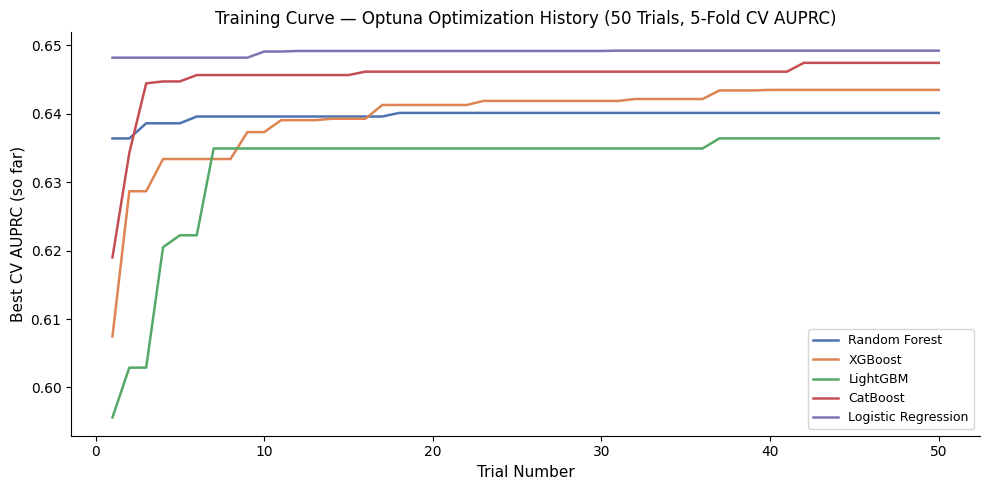

In [12]:
# ── Training Curve — Optuna Optimization History ────────────────────────────────
# Running best CV AUPRC over 50 TPE trials per model.
# Plateau early → converged; still rising at trial 50 → more budget may help.

_opt_colors = {
    'Random Forest':       '#4C72B0',
    'XGBoost':             '#DD8452',
    'LightGBM':            '#55A868',
    'CatBoost':            '#C44E52',
    'Logistic Regression': '#8172B2',
}

fig, ax = plt.subplots(figsize=(10, 5))
for name, info in results.items():
    trial_vals  = [t.value for t in info['study'].trials if t.value is not None]
    best_so_far = np.maximum.accumulate(trial_vals)
    ax.plot(range(1, len(best_so_far) + 1), best_so_far,
            linewidth=1.8, label=name, color=_opt_colors.get(name))

ax.set_xlabel('Trial Number', fontsize=11)
ax.set_ylabel('Best CV AUPRC (so far)', fontsize=11)
ax.set_title('Training Curve — Optuna Optimization History (50 Trials, 5-Fold CV AUPRC)', fontsize=12)
ax.legend(loc='lower right', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 9.1 Refit Tuned Models & Select Best by OOF AUPRC </h3>

Same selection rule as the main pipeline: rank by out-of-fold AUPRC on the 2020-2023 training folds (never sees 2024), no forced pin to any one classifier.


In [13]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict

def build_estimator(name, params):
    if name == "Random Forest":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", RandomForestClassifier(
                class_weight="balanced", random_state=42, n_jobs=-1, **params))
        ])
    if name == "XGBoost":
        # scale_pos_weight is PINNED in §8 and no longer tuned, so it should not appear in
        # best_params. Strip it defensively: a `results` dict left over from a session where
        # it WAS tuned would otherwise raise "got multiple values for keyword argument
        # 'scale_pos_weight'" on a partial re-run of this cell.
        params = {k: v for k, v in params.items() if k != "scale_pos_weight"}
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", XGBClassifier(
                scale_pos_weight=SCALE_POS_WEIGHT,
                eval_metric="logloss", random_state=42, nthread=1, **params))
        ])
    if name == "LightGBM":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", LGBMClassifier(
                class_weight="balanced", verbose=-1, random_state=42, n_jobs=1, **params))
        ])
    if name == "CatBoost":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", CatBoostClassifier(
                auto_class_weights="Balanced", random_seed=42, verbose=0, **params))
        ])
    if name == "Logistic Regression":
        return Pipeline([
            ("imputer", make_imputer()),
            ("scaler", make_scaler()),   # continuous only -- dummies stay 0/1, see §6
            # penalty inferred from l1_ratio (arrives via **params) -- see §8. The explicit
            # penalty= argument is removed in scikit-learn 1.10.
            ("model", LogisticRegression(
                class_weight="balanced",
                solver="saga", max_iter=1000, random_state=42, **params))
        ])
    raise ValueError(name)

def _xgb_oof_proba(params):
    # Mirrors §8's obj_xgb: cross_val_predict would clone build_estimator's XGBoost pipeline
    # (frozen at the full-training-set SCALE_POS_WEIGHT) onto every fold, so XGBoost's OOF
    # predictions would be the only ones NOT using a fold-local class-balance ratio -- RF /
    # LightGBM / LR resolve 'balanced' and CatBoost resolves 'Balanced' fresh inside each
    # fold cross_val_predict fits. This loop gives XGBoost the same fold-local treatment.
    _params = {k: v for k, v in params.items() if k != "scale_pos_weight"}
    oof = np.zeros(len(X_train))
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr        = y_train.iloc[train_idx]
        fold_spw    = float((y_tr == 0).sum() / (y_tr == 1).sum())
        fold_model = Pipeline([
            ("imputer", make_imputer()),
            ("model", XGBClassifier(
                scale_pos_weight=fold_spw,
                eval_metric="logloss", random_state=42, nthread=1, **_params))
        ])
        fold_model.fit(X_tr, y_tr)
        oof[val_idx] = fold_model.predict_proba(X_val)[:, 1]
    return oof

fitted_models = {}
oof_proba_by_model = {}
rows = []
for name, info in results.items():
    est = build_estimator(name, info["best_params"])
    if name == "XGBoost":
        _oof_proba = _xgb_oof_proba(info["best_params"])
    else:
        _oof_proba = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_proba_by_model[name] = _oof_proba
    oof_auprc  = average_precision_score(y_train, _oof_proba)
    est.fit(X_train, y_train)
    fitted_models[name] = est
    proba = est.predict_proba(X_test)[:, 1]
    # Test metrics are SURVEY-WEIGHTED (population estimates). CV/OOF above stay unweighted:
    # they drive model SELECTION, an internal choice made on the development sample.
    test_auc   = roc_auc_score(y_test, proba, sample_weight=w_test_arr)
    test_auprc = average_precision_score(y_test, proba, sample_weight=w_test_arr)
    rows.append({"Model": name,
                 "CV AUPRC":     info["best_cv_score"],
                 "OOF AUPRC":  oof_auprc,
                 "Test AUC":   test_auc,
                 "Test AUPRC": test_auprc})

# Rank by OOF AUPRC -- out-of-fold predictions on the 2020-2023 TRAINING data only.
#
# Selecting on Test AUPRC (the previous behaviour) makes every reported 2024 number a
# maximum over 5 candidate models, so the hold-out stops functioning as a hold-out and
# the optimism propagates into everything keyed on best_name: SHAP, top_shap_vars, the
# SHAP-informed regression in §9, the Youden/MCC thresholds, DCA and calibration. The
# bootstrap CIs in §9 do not cover that selection bias.
#
# OOF AUPRC is also the better choice over Optuna's own best_cv_score ("CV AUPRC"),
# which is the maximum over 50 trials and therefore optimistically biased; the OOF
# column re-scores the single chosen configuration on held-out folds.
#
# Test AUPRC / Test AUC remain in the table -- reported, never used to choose.
eval_df = (pd.DataFrame(rows)
             .set_index("Model")
             .sort_values("OOF AUPRC", ascending=False))
print(eval_df.round(4).to_string())
print("CAPTION: 'CV AUPRC' and 'OOF AUPRC' are UNWEIGHTED -- selection metrics computed on"
      "\nthe 2020-2023 development sample. 'Test AUC' and 'Test AUPRC' are SURVEY-WEIGHTED"
      "\npopulation estimates on the 2024 hold-out. Compare down a column, not across a row."
      "\nSelection is unweighted by design, so the selected model need not have the best"
      "\nweighted test score -- that is the hold-out working, not an inconsistency.")

best_name  = eval_df.index[0]  # selected by OOF AUPRC -- leakage-free, never sees 2024
best_model = fitted_models[best_name]
print(f'Best model by OOF AUPRC: {best_name} (OOF AUPRC = {eval_df.loc[best_name, "OOF AUPRC"]:.4f})'
      f' | Test AUPRC: {eval_df.loc[best_name, "Test AUPRC"]:.4f}'
      f' | Test AUC: {eval_df.loc[best_name, "Test AUC"]:.4f}'
      f' | Optuna CV AUPRC: {eval_df.loc[best_name, "CV AUPRC"]:.4f}')

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


                     CV AUPRC  OOF AUPRC  Test AUC  Test AUPRC
Model                                                         
Logistic Regression    0.6492     0.6455    0.7046      0.6173
CatBoost               0.6474     0.6436    0.7012      0.6106
XGBoost                0.6435     0.6388    0.6991      0.6207
Random Forest          0.6401     0.6361    0.7012      0.6214
LightGBM               0.6364     0.6336    0.6950      0.6126
CAPTION: 'CV AUPRC' and 'OOF AUPRC' are UNWEIGHTED -- selection metrics computed on
the 2020-2023 development sample. 'Test AUC' and 'Test AUPRC' are SURVEY-WEIGHTED
population estimates on the 2024 hold-out. Compare down a column, not across a row.
Selection is unweighted by design, so the selected model need not have the best
weighted test score -- that is the hold-out working, not an inconsistency.
Best model by OOF AUPRC: Logistic Regression (OOF AUPRC = 0.6455) | Test AUPRC: 0.6173 | Test AUC: 0.7046 | Optuna CV AUPRC: 0.6492


<h3 style="color:yellow";> 9.2 Bootstrap 95% CIs — Test-Set Metrics </h3>

2,000 stratified resamples, identical procedure to the main pipeline.


In [14]:
# ── Test-set Accuracy/Recall/Precision/F1/AUROC, OOF AUPRC and survey-weighted Test AUPRC with bootstrap 95% CIs ──
# Accuracy/Recall/Specificity/Precision/F1 are evaluated at each model's MCC-optimal threshold: the
# threshold that maximizes Matthews correlation coefficient on that model's OOF training
# probabilities. This mirrors §12's confusion-matrix threshold selection but is computed
# independently here (rather than reusing §12's mcc_curve) so this cell stays
# self-contained and doesn't depend on §12 having already run -- same convention used
# elsewhere in this notebook. The threshold is picked purely from OOF/train predictions
# and never touches the test set.
#
# Accuracy/Recall/Precision/F1 and AUROC are computed on the 2024 hold-out test rows,
# survey-weighted (wt_itvex), with a 95% CI from a stratified (prevalence-preserving)
# bootstrap of those rows -- the SAME resamples for every metric and model, so
# comparisons stay paired. AUPRC is OOF AUPRC -- out-of-fold average precision on the
# 2020-2023 training folds, i.e. §9.1's selection metric -- UNWEIGHTED, with its own 95%
# CI from a stratified bootstrap of the training rows, matching §9.1's convention that
# selection metrics are computed on the unweighted development sample. 'Test AUPRC' is
# the survey-weighted average precision on the 2024 hold-out (the §9.1 eval_df value),
# added beside OOF AUPRC with a 95% CI from the SAME test-row bootstrap as the other
# weighted metrics -- reported, never used for selection.
#
# Both bootstraps: 2000 resamples, fixed seed -> fully reproducible on "Run All".
# Depends on fitted_models / oof_proba_by_model / X_test / y_test / y_train from
# the model-evaluation cell (§9.1).
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                              recall_score, precision_score, f1_score, roc_curve,
                              confusion_matrix)

N_BOOT_CI = 2000
_yte = y_test.to_numpy()
_wte = w_test.to_numpy()      # survey weights, applied to every test-set metric
_idx0 = np.where(_yte == 0)[0]
_idx1 = np.where(_yte == 1)[0]

_ytr = y_train.to_numpy()
_idx0_tr = np.where(_ytr == 0)[0]
_idx1_tr = np.where(_ytr == 1)[0]

# Draw the bootstrap resamples ONCE so every model/metric is scored on the same rows (paired)
_rng_ci = np.random.default_rng(42)
_boot_idx = [
    np.concatenate([_rng_ci.choice(_idx0, _idx0.size, replace=True),
                    _rng_ci.choice(_idx1, _idx1.size, replace=True)])
    for _ in range(N_BOOT_CI)
]
_boot_idx_tr = [
    np.concatenate([_rng_ci.choice(_idx0_tr, _idx0_tr.size, replace=True),
                    _rng_ci.choice(_idx1_tr, _idx1_tr.size, replace=True)])
    for _ in range(N_BOOT_CI)
]

def _mcc_optimal_threshold(y_true, oof_proba):
    # Vectorised MCC sweep over OOF ROC thresholds -- same trick as §12's mcc_curve
    # (sort scores once, walk the cut-point down as a running confusion-matrix total),
    # duplicated here rather than imported so this cell doesn't depend on §12's order.
    y = np.asarray(y_true, dtype=np.int64)
    p = np.asarray(oof_proba, dtype=float)
    _, _, thresh_oof = roc_curve(y, p)
    order    = np.argsort(-p, kind='mergesort')
    y_sorted = y[order]
    p_sorted = p[order]
    P = int(y.sum())
    N = y.size - P
    k = np.searchsorted(-p_sorted, -thresh_oof, side='right')
    cum_tp = np.concatenate(([0], np.cumsum(y_sorted)))
    TP = cum_tp[k].astype(float)
    FP = k - TP
    FN = P - TP
    TN = N - FP
    denom = np.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN))
    with np.errstate(invalid='ignore', divide='ignore'):
        mcc = (TP * TN - FP * FN) / denom
    mcc = np.where(denom == 0, 0.0, mcc)
    return float(thresh_oof[int(np.argmax(mcc))])

def _boot_ci_test(values, metric):
    # weights are indexed alongside y/values so each resample carries its own rows' weights
    vals = np.fromiter(
        (metric(_yte[bi], values[bi], sample_weight=_wte[bi]) for bi in _boot_idx),
        dtype=float, count=N_BOOT_CI)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return lo, hi

def _boot_ci_oof(oof_proba):
    # unweighted, resampled over the training rows -- mirrors §9.1's OOF AUPRC convention
    vals = np.fromiter(
        (average_precision_score(_ytr[bi], oof_proba[bi]) for bi in _boot_idx_tr),
        dtype=float, count=N_BOOT_CI)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return lo, hi

_metric_fns = {
    "Accuracy":    lambda y, pred, sample_weight: accuracy_score(y, pred, sample_weight=sample_weight),
    "Recall":      lambda y, pred, sample_weight: recall_score(y, pred, sample_weight=sample_weight, zero_division=0),
    "Specificity": lambda y, pred, sample_weight: recall_score(y, pred, pos_label=0, sample_weight=sample_weight, zero_division=0),
    "Precision":   lambda y, pred, sample_weight: precision_score(y, pred, sample_weight=sample_weight, zero_division=0),
    "F1":          lambda y, pred, sample_weight: f1_score(y, pred, sample_weight=sample_weight, zero_division=0),
}

_rows_ci = []
for _name, _model in fitted_models.items():
    _p      = _model.predict_proba(X_test)[:, 1]
    _oof_p  = oof_proba_by_model[_name]
    _thresh = _mcc_optimal_threshold(_ytr, _oof_p)
    _preds  = (_p >= _thresh).astype(int)

    _pt = {m: fn(_yte, _preds, sample_weight=_wte) for m, fn in _metric_fns.items()}
    _pt["AUROC"]     = roc_auc_score(_yte, _p, sample_weight=_wte)
    _pt["OOF AUPRC"] = average_precision_score(_ytr, _oof_p)
    _pt["Test AUPRC"] = average_precision_score(_yte, _p, sample_weight=_wte)

    # Cross-check: Sensitivity/Specificity recomputed directly from TP/FP/FN/TN of a
    # sample-weighted confusion matrix, confirming they match the recall_score values above.
    _tn, _fp, _fn, _tp = confusion_matrix(_yte, _preds, sample_weight=_wte).ravel()
    _sens_check = _tp / (_tp + _fn)
    _spec_check = _tn / (_tn + _fp)
    assert np.isclose(_sens_check, _pt["Recall"]) and np.isclose(_spec_check, _pt["Specificity"]), \
        f"{_name}: confusion-matrix check mismatch"
    print(f"  [check] {_name}: Sensitivity = TP/(TP+FN) = {_sens_check:.3f}, "
          f"Specificity = TN/(TN+FP) = {_spec_check:.3f}")

    _ci = {m: _boot_ci_test(_preds, fn) for m, fn in _metric_fns.items()}
    _ci["AUROC"]     = _boot_ci_test(_p, roc_auc_score)
    _ci["OOF AUPRC"] = _boot_ci_oof(_oof_p)
    _ci["Test AUPRC"] = _boot_ci_test(_p, average_precision_score)

    _row = {"Model": _name, "Threshold (MCC-opt., OOF)": f"{_thresh:.3f}"}
    for m in ("Accuracy", "Recall", "Specificity", "Precision", "F1", "AUROC", "OOF AUPRC", "Test AUPRC"):
        _row[f"{m} (95% CI)"] = f"{_pt[m]:.3f} ({_ci[m][0]:.3f}–{_ci[m][1]:.3f})"
    _rows_ci.append(_row)

metrics_ci_df = pd.DataFrame(_rows_ci).set_index("Model")
print(f"Test-set Accuracy/Recall/Specificity/Precision/F1/AUROC (95% CI), OOF AUPRC (95% CI) and "
      f"survey-weighted Test AUPRC (95% CI) "
      f"-- classification metrics at each model's OOF MCC-optimal threshold "
      f"(n_test={len(_yte)}, n_train={len(_ytr)}, {N_BOOT_CI} stratified resamples, seed=42)")
print(metrics_ci_df.to_string())


  [check] Random Forest: Sensitivity = TP/(TP+FN) = 0.651, Specificity = TN/(TN+FP) = 0.636


  [check] XGBoost: Sensitivity = TP/(TP+FN) = 0.518, Specificity = TN/(TN+FP) = 0.764


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  [check] LightGBM: Sensitivity = TP/(TP+FN) = 0.531, Specificity = TN/(TN+FP) = 0.749


  [check] CatBoost: Sensitivity = TP/(TP+FN) = 0.523, Specificity = TN/(TN+FP) = 0.776


  [check] Logistic Regression: Sensitivity = TP/(TP+FN) = 0.602, Specificity = TN/(TN+FP) = 0.691


Test-set Accuracy/Recall/Specificity/Precision/F1/AUROC (95% CI), OOF AUPRC (95% CI) and survey-weighted Test AUPRC (95% CI) -- classification metrics at each model's OOF MCC-optimal threshold (n_test=1758, n_train=5946, 2000 stratified resamples, seed=42)
                    Threshold (MCC-opt., OOF)    Accuracy (95% CI)      Recall (95% CI) Specificity (95% CI)   Precision (95% CI)          F1 (95% CI)       AUROC (95% CI)   OOF AUPRC (95% CI)  Test AUPRC (95% CI)
Model                                                                                                                                                                                                                
Random Forest                           0.454  0.642 (0.618–0.666)  0.651 (0.611–0.688)  0.636 (0.603–0.667)  0.546 (0.519–0.573)  0.594 (0.566–0.621)  0.701 (0.674–0.728)  0.636 (0.620–0.653)  0.621 (0.589–0.655)
XGBoost                                 0.533  0.665 (0.641–0.688)  0.518 (0.477–0.557)  0.764 (0.737

<h3 style="color:yellow";> 9.3 Platt Recalibration Diagnostics </h3>

Same class-weighting + Platt recalibration procedure as the main pipeline (§12.2.0): unpenalised logistic recalibrator fit on OOF training probabilities, evaluated on the 2024 test set (Brier score, ECE, survey-weighted).


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters


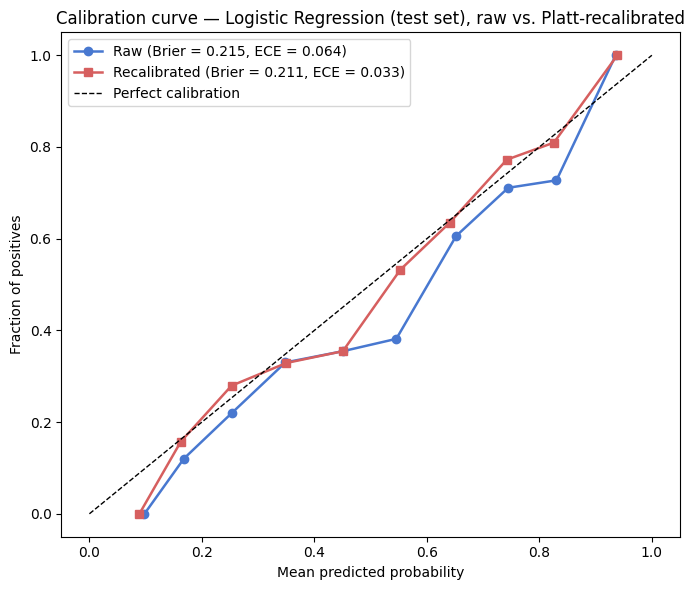


Post-hoc recalibration — all tuned models (n_test=1758):
                      Slope  Intercept  Brier (raw)  Brier (recalibrated)  ECE (raw)  ECE (recalibrated)
Model                                                                                                   
Random Forest        1.2917    -0.1424       0.2148                0.2111     0.0625              0.0304
XGBoost              1.1384    -0.1991       0.2160                0.2121     0.0685              0.0325
LightGBM             1.0602    -0.2092       0.2179                0.2136     0.0686              0.0346
CatBoost             1.0754    -0.2206       0.2160                0.2117     0.0672              0.0247
Logistic Regression  0.9721    -0.2282       0.2149                0.2106     0.0637              0.0333


In [15]:
# ── §12.2.0 Calibration curve — raw vs. Platt-recalibrated (best model) ──────────
# `class_weight="balanced"` / `scale_pos_weight` shift predicted probabilities away from
# true prevalence -- the same direction SMOTE would, which §11 explicitly avoided SMOTE
# for. Recalibration is fit on out-of-fold TRAIN probabilities (oof_proba_by_model, §7)
# only; the test set is untouched until the comparison below. The recalibrator's own
# coefficients (slope, intercept) double as the calibration diagnostics.
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression

def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def _ece(y_true, y_prob, sample_weight=None, n_bins=10):
    # Expected Calibration Error -- uniform [0, 1] bins. Survey-weighted (sample_weight)
    # so it sits on the same footing as the Brier columns below; the plotted calibration
    # CURVE stays unweighted (calibration_curve takes no weights), the same split noted
    # for Brier further down. Per-bin weight = share of (weighted) samples landing in it.
    y_true = np.asarray(y_true, dtype=float)
    y_prob = np.asarray(y_prob, dtype=float)
    w = np.ones_like(y_prob) if sample_weight is None else np.asarray(sample_weight, dtype=float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    b_idx = np.clip(np.digitize(y_prob, edges[1:-1]), 0, n_bins - 1)
    total_w = w.sum()
    ece = 0.0
    for b in range(n_bins):
        m = b_idx == b
        w_b = w[m].sum()
        if w_b == 0:
            continue
        conf = np.average(y_prob[m], weights=w[m])
        acc = np.average(y_true[m], weights=w[m])
        ece += (w_b / total_w) * abs(acc - conf)
    return ece

recal_rows = []
recal_proba_by_model = {}
for name, model in fitted_models.items():
    proba_raw = model.predict_proba(X_test)[:, 1]

    # C=np.inf: Platt scaling must be UNPENALISED. LogisticRegression() defaults to
    # L2 with C=1, which shrinks the fitted slope toward 0 -- and the slope/intercept are
    # themselves reported below as the calibration diagnostic, so a shrunk slope would
    # misstate the very quantity this cell exists to measure.
    # C=np.inf replaces the deprecated penalty=None (removed in scikit-learn 1.10);
    # coefficients are bit-identical. sklearn 1.8 emits a cosmetic UserWarning here.
    recalibrator = LogisticRegression(C=np.inf).fit(
        _logit(oof_proba_by_model[name]).reshape(-1, 1), y_train)
    slope, intercept = recalibrator.coef_[0, 0], recalibrator.intercept_[0]
    proba_recal = recalibrator.predict_proba(_logit(proba_raw).reshape(-1, 1))[:, 1]
    recal_proba_by_model[name] = proba_recal

    recal_rows.append({
        "Model": name,
        "Slope": slope,
        "Intercept": intercept,
        # Test Brier scores are survey-weighted; the recalibrator itself is FITTED on
        # unweighted training OOF probabilities, since fitting stays unweighted throughout.
        "Brier (raw)": brier_score_loss(y_test, proba_raw, sample_weight=w_test_arr),
        "Brier (recalibrated)": brier_score_loss(y_test, proba_recal, sample_weight=w_test_arr),
        "ECE (raw)": _ece(y_test, proba_raw, sample_weight=w_test_arr),
        "ECE (recalibrated)": _ece(y_test, proba_recal, sample_weight=w_test_arr),
    })

recal_df = pd.DataFrame(recal_rows).set_index("Model")

# ── Plot: best_name only, raw vs. Platt-recalibrated ──────────────────────────────
# calibration_curve accepts no sample_weight, so the plotted CURVES are unweighted
# (sample-level) while the Brier / ECE scores in the legend are survey-weighted -- the two
# are not on the same footing.
proba_best_raw = best_model.predict_proba(X_test)[:, 1]
proba_best_recal = recal_proba_by_model[best_name]
brier_raw = brier_score_loss(y_test, proba_best_raw, sample_weight=w_test_arr)
brier_recal = brier_score_loss(y_test, proba_best_recal, sample_weight=w_test_arr)
ece_raw = _ece(y_test, proba_best_raw, sample_weight=w_test_arr)
ece_recal = _ece(y_test, proba_best_recal, sample_weight=w_test_arr)

prob_true_raw, prob_pred_raw = calibration_curve(y_test, proba_best_raw, n_bins=10, strategy='uniform')
prob_true_recal, prob_pred_recal = calibration_curve(y_test, proba_best_recal, n_bins=10, strategy='uniform')

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(prob_pred_raw, prob_true_raw, marker='o', linewidth=1.8, color='#4878d0',
        label=f'Raw (Brier = {brier_raw:.3f}, ECE = {ece_raw:.3f})')
ax.plot(prob_pred_recal, prob_true_recal, marker='s', linewidth=1.8, color='#d65f5f',
        label=f'Recalibrated (Brier = {brier_recal:.3f}, ECE = {ece_recal:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title(f'Calibration curve — {best_name} (test set), raw vs. Platt-recalibrated')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"\nPost-hoc recalibration — all tuned models (n_test={len(y_test)}):")
print(recal_df.round(4).to_string())


<h2 style="color:#FFA500";> 10. Deliverables </h2>


<h3 style="color:yellow";> 10.1 Results Table (Table 2 style) </h3>


In [16]:
# ── Deliverable 1 — Results table (Table 2 style), reduced feature set ───────────
# Same layout as the manuscript's Table 2: one row per classifier, headline metrics
# with 95% CIs. Pulled straight from metrics_ci_df (§9.2, bootstrap CIs) plus the
# selection-relevant CV/OOF/Test AUPRC columns from eval_df (§9.1).
table2_cols = ["AUROC (95% CI)", "OOF AUPRC (95% CI)", "Test AUPRC (95% CI)",
               "Accuracy (95% CI)", "Recall (95% CI)", "Specificity (95% CI)",
               "Precision (95% CI)", "F1 (95% CI)"]
results_table_65plus = metrics_ci_df[table2_cols].copy()
results_table_65plus.insert(0, "CV AUPRC", eval_df.loc[results_table_65plus.index, "CV AUPRC"].round(4))

print(f"Table 2 (sensitivity, no oral-domain features) — Cohort 65plus")
print(results_table_65plus.to_string())


Table 2 (sensitivity, no oral-domain features) — Cohort 65plus
                     CV AUPRC       AUROC (95% CI)   OOF AUPRC (95% CI)  Test AUPRC (95% CI)    Accuracy (95% CI)      Recall (95% CI) Specificity (95% CI)   Precision (95% CI)          F1 (95% CI)
Model                                                                                                                                                                                                
Random Forest          0.6401  0.701 (0.674–0.728)  0.636 (0.620–0.653)  0.621 (0.589–0.655)  0.642 (0.618–0.666)  0.651 (0.611–0.688)  0.636 (0.603–0.667)  0.546 (0.519–0.573)  0.594 (0.566–0.621)
XGBoost                0.6435  0.699 (0.671–0.726)  0.639 (0.622–0.655)  0.621 (0.588–0.655)  0.665 (0.641–0.688)  0.518 (0.477–0.557)  0.764 (0.737–0.791)  0.596 (0.560–0.632)  0.554 (0.520–0.587)
LightGBM               0.6364  0.695 (0.667–0.722)  0.634 (0.617–0.650)  0.613 (0.577–0.647)  0.661 (0.638–0.685)  0.531 (0.491–0.569)  0.749 (0.

<h3 style="color:yellow";> 10.2 Best Model Flag </h3>


In [17]:
# ── Deliverable 2 — Best model under the OOF-AUPRC selection rule ────────────────
print(f"Cohort 65plus — best model (OOF AUPRC, no oral-domain features): {best_name}")
if best_name != "CatBoost":
    print(f"  -> DIFFERS from CatBoost, the common model selected in the main (full-feature) paper.")
else:
    print(f"  -> Matches CatBoost, the common model selected in the main (full-feature) paper.")
print(eval_df.round(4).to_string())


Cohort 65plus — best model (OOF AUPRC, no oral-domain features): Logistic Regression
  -> DIFFERS from CatBoost, the common model selected in the main (full-feature) paper.
                     CV AUPRC  OOF AUPRC  Test AUC  Test AUPRC
Model                                                         
Logistic Regression    0.6492     0.6455    0.7046      0.6173
CatBoost               0.6474     0.6436    0.7012      0.6106
XGBoost                0.6435     0.6388    0.6991      0.6207
Random Forest          0.6401     0.6361    0.7012      0.6214
LightGBM               0.6364     0.6336    0.6950      0.6126


<h3 style="color:yellow";> 10.3 Comparison vs. Main Paper (Full-Feature) Numbers </h3>


In [18]:
# ── Deliverable 3 — Gap vs. the main paper's full-feature numbers ────────────────
# Reference values are the manuscript's full-feature (43 raw / oral-domain included)
# common-model (CatBoost) test-set numbers for this cohort, hardcoded from the paper.
REF_AUROC_65plus = 0.76
REF_AUPRC_65plus = 0.69

_best_auroc = eval_df.loc[best_name, "Test AUC"]
_best_auprc = eval_df.loc[best_name, "Test AUPRC"]

print(f"Cohort ≥65 — reduced (no oral-domain) vs. full-feature (main paper):")
print(f"  Best model here: {best_name}")
print(f"  AUROC: {_best_auroc:.3f}  vs. full-feature {REF_AUROC_65plus:.3f}  "
      f"(Δ = {_best_auroc - REF_AUROC_65plus:+.3f})")
print(f"  AUPRC: {_best_auprc:.3f}  vs. full-feature {REF_AUPRC_65plus:.3f}  "
      f"(Δ = {_best_auprc - REF_AUPRC_65plus:+.3f})")
print()
print("Note: full-feature reference numbers are hardcoded from the main paper, not "
      "recomputed here -- confirm they still match the current main pipeline's output "
      "before citing this comparison.")


Cohort ≥65 — reduced (no oral-domain) vs. full-feature (main paper):
  Best model here: Logistic Regression
  AUROC: 0.705  vs. full-feature 0.760  (Δ = -0.055)
  AUPRC: 0.617  vs. full-feature 0.690  (Δ = -0.073)

Note: full-feature reference numbers are hardcoded from the main paper, not recomputed here -- confirm they still match the current main pipeline's output before citing this comparison.
